In [1]:
# may be useful: https://github.com/mdmould/h5ify
# the two sims we're using are SM5_DFD_3_TNG and SM5_LW10_DFD3_TNG

In [1]:
from cosmo_sim_tools.arepo_tools import arepo_package
import sys
sys.path.append('../py_files')
import subhalo_dict
import wandering_bh_catalog as catalog
import h5py
import matplotlib.pyplot as plt
import numpy as np

In [3]:
#Brahma_sim_path = '/orange/lblecha/aklantbhowmick/GAS_BASED_SEED_MODEL_UNIFORM_RUNS/L12p5n512/AREPO/'
#Brahma_sim_name = 'SM5_DFD_3_TNG/'
#Brahma_sim_file = Brahma_sim_path+Brahma_sim_name

In [4]:
# snapshots, redshifts = arepo_package.get_snapshot_redshift_correspondence(Brahma_sim_file)

In [5]:
#subhalo_dict.make_dict(Brahma_sim_file, redshifts, 25, 3) #file, redshift array, chosen snapnum, num subhalos

In [6]:
# %run ../py_files/wandering_bh_catalog.py

In [7]:
#catalog.snapshot_rows(Brahma_sim_file, 8, redshifts[8], max_subhalos=None)

In [8]:
#catalog.snapshot_rows

In [12]:
with h5py.File("/orange/lblecha/pranavsatheesh/wandering_bhs/Data/wandering_bh_SM5_DFD_3_TNG.hdf5") as f:
    is_wandering = f["bh/is_wandering"][:]
    r_kpc = f["bh/r_kpc"] # all radii
    wandering_r_kpc = f["bh/r_kpc"][is_wandering]          # distances of just the wandering BHs
    nonwander_r_kpc = f["bh/r_kpc"][np.invert(is_wandering)]      # distances of all other BHs
    lum = f["bh/lbol_erg_s"] # all lum
    wandering_lum = f["bh/lbol_erg_s"][is_wandering]       # luminosities of wanderers
    nonwander_lum = f["bh/lbol_erg_s"][np.invert(is_wandering)]    # luminosities of others

    snapchoice = 7                                                     # CHANGE SNAPSHOT HERE
    num_halos_in_snap = f["snapshot/n_subhalos_with_bh"][snapchoice]
    subhalochoice = 2 % num_halos_in_snap                               # CHANGE SUBHALO HERE
    subhalo_start = f["snapshot/subhalo_start"][snapchoice]
    bh_start = f["subhalo/bh_start"][subhalo_start+subhalochoice]
    halfmass_rad = f["subhalo/stellar_halfrad_kpc"][subhalo_start+subhalochoice]
    num_bh_in_halo = f["subhalo/bh_count"][subhalo_start+subhalochoice]
    wandering_in_halo = is_wandering[bh_start:bh_start+num_bh_in_halo]
    r_in_halo = r_kpc[bh_start:bh_start+num_bh_in_halo]
    r_wand_in_halo = r_in_halo[wandering_in_halo]
    r_nonwand_in_halo = r_in_halo[np.invert(wandering_in_halo)]
    lum_in_halo = lum[bh_start:bh_start+num_bh_in_halo]
    lum_wand_in_halo = lum_in_halo[wandering_in_halo]
    lum_nonwand_in_halo = lum_in_halo[np.invert(wandering_in_halo)]

In [36]:
num_halos_in_snap, subhalo_start, bh_start, num_bh_in_halo

(np.int32(0), np.int64(0), np.int64(0), np.int32(1))

In [37]:
wandering_in_halo, r_in_halo, r_wand_in_halo, r_nonwand_in_halo, lum_in_halo, lum_wand_in_halo, lum_nonwand_in_halo

(array([False]),
 array([7.083367e-14], dtype=float32),
 array([], dtype=float32),
 array([7.083367e-14], dtype=float32),
 array([4.86260592e+40]),
 array([], dtype=float64),
 array([4.86260592e+40]))

Text(0.5, 1.0, 'Lum vs rad for subhalo 2 of snap 7')

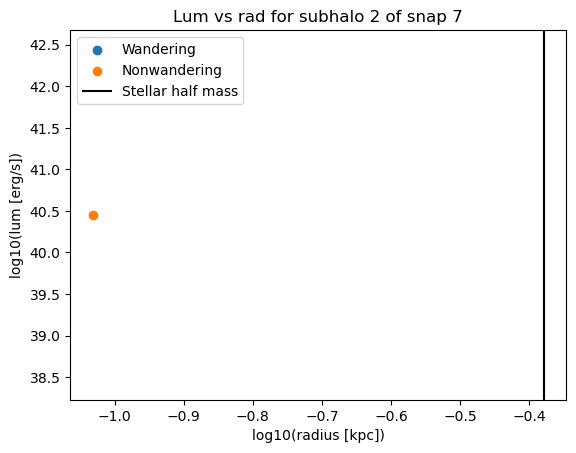

In [13]:
plt.scatter(np.log10(r_wand_in_halo), np.log10(lum_wand_in_halo), label="Wandering")
plt.scatter(np.log10(r_nonwand_in_halo), np.log10(lum_nonwand_in_halo), label="Nonwandering")
plt.axvline(np.log10(halfmass_rad), color="k", label="Stellar half mass")
plt.legend()
plt.xlabel("log10(radius [kpc])")
plt.ylabel("log10(lum [erg/s])")
plt.title(f"Lum vs rad for subhalo {subhalochoice} of snap {snapchoice}") 

In [ ]:
#NOTE: add marking for resolution, find culprit for very low lograds. maybe bh mass >>> rest of halo
# possible other plots: scale radius by sybhalo virial radius, plot diff stellar mass intervals (see ricarte study) 

3789
processing subhalo 0


/tmp/ipykernel_2389755/2890666907.py:18: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(r_in_halo), np.log10(lum_in_halo)) #, label=str(subhalochoice))


processing subhalo 100
processing subhalo 200
processing subhalo 300
processing subhalo 400
processing subhalo 500
processing subhalo 600
processing subhalo 700
processing subhalo 800
processing subhalo 900
processing subhalo 1000
processing subhalo 1100
processing subhalo 1200
processing subhalo 1300
processing subhalo 1400
processing subhalo 1500
processing subhalo 1600
processing subhalo 1700
processing subhalo 1800
processing subhalo 1900
processing subhalo 2000
processing subhalo 2100
processing subhalo 2200
processing subhalo 2300
processing subhalo 2400
processing subhalo 2500
processing subhalo 2600
processing subhalo 2700
processing subhalo 2800
processing subhalo 2900
processing subhalo 3000
processing subhalo 3100
processing subhalo 3200
processing subhalo 3300
processing subhalo 3400
processing subhalo 3500
processing subhalo 3600
processing subhalo 3700


Text(0.5, 1.0, 'Lum vs rad for subhalo of snap 19')

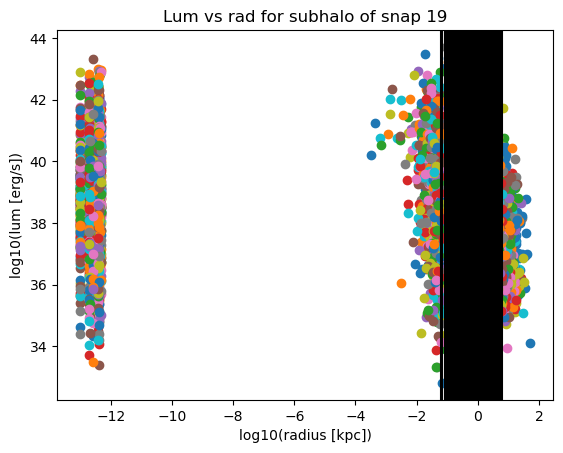

In [16]:
with h5py.File("/orange/lblecha/pranavsatheesh/wandering_bhs/Data/wandering_bh_SM5_DFD_3_TNG.hdf5") as f:
    is_wandering = f["bh/is_wandering"][:]
    r_kpc = f["bh/r_kpc"] # all radii
    lum = f["bh/lbol_erg_s"] # all lum
    
    snapchoice = 19                                           # CHANGE SNAPSHOT HERE
    num_halos_in_snap = f["snapshot/n_subhalos_with_bh"][snapchoice]
    print(num_halos_in_snap)
    for subhalochoice in range(num_halos_in_snap):
        if subhalochoice % 100 == 0: print(f"processing subhalo {subhalochoice}")
        subhalo_start = f["snapshot/subhalo_start"][snapchoice]
        bh_start = f["subhalo/bh_start"][subhalo_start+subhalochoice]
        halfmass_rad = f["subhalo/stellar_halfrad_kpc"][subhalo_start+subhalochoice]
        num_bh_in_halo = f["subhalo/bh_count"][subhalo_start+subhalochoice]
        wandering_in_halo = is_wandering[bh_start:bh_start+num_bh_in_halo]
        r_in_halo = r_kpc[bh_start:bh_start+num_bh_in_halo]
        lum_in_halo = lum[bh_start:bh_start+num_bh_in_halo]
        plt.scatter(np.log10(r_in_halo), np.log10(lum_in_halo)) #, label=str(subhalochoice))
        plt.axvline(np.log10(halfmass_rad), color="k")
#plt.legend()
plt.xlabel("log10(radius [kpc])")
plt.ylabel("log10(lum [erg/s])")
plt.title(f"Lum vs rad for subhalo of snap {snapchoice}") 

In [ ]:
# it looks like every snap that has viable halos also has extracentral bhs. snap 7 has 4 halos, two have a single bh at 10^-13, two have a single bh at 10^-2. 
# in future snapshots, well-behaved BHs are more common, but there are always the extracentrals. 